# PA 2025 Unet implementation on TM 2025-26 synthetic data

Most of this document is a take directly from my PA "Astronomical Adaptive Optics Point Spread Function Reconstruction with Machine Learning Algorithms" (HES-SO master, 1001, Lausanne) with some minor adjustments to make it work with PyTorch.

## Inputs

In [30]:
outputDir = "output_ML/"
inputDir = "output_prep/"
stabilisation_delay = 100

rng_SEED = 42
train_split = 0.8

GPU = True

SMALL_SIZE = 20
MEDIUM_SIZE = 20
BIGGER_SIZE = 25

In [24]:
import os
os.environ["KERAS_BACKEND"] = "torch"
import torch
import keras
import h5py
import numpy as np
import matplotlib.pyplot as plt

In [68]:
def pixel_adder(data, scale_factor = [1,1], final_shape = None):
    """
    Generates a phase screen base on a Phase Spectrum Density (PSD)
    Parameters:
        data (ndarray): source data
        scale_factor (floar): scalling factor. Can be > or < o
        final_shape (ndarray): Option to input directly the desired shape. final_shape/data.shape must be an integer or the final shape will be data.shape*(final_shape//data.shape).
    Returns (list):
        D_phi (ndarray): 2D array representing the phase structure
    TODO: Error check
    """

    datashape = data.shape

    if final_shape == None:
        iscale = scale_factor[0]
        jscale = scale_factor[1]
        image_scaled = np.zeros((int(scale_factor[0]*datashape[0]), int(scale_factor[1]*datashape[1])))
    else:
        iscale = datashape[0]*(final_shape[0]/datashape[0])
        jscale = datashape[1]*(final_shape[1]/datashape[1])
        image_scaled = np.zeros((int(final_shape[0]), int(final_shape[1])))

    for i in range(0, datashape[0]):
        for j in range(0, datashape[1]):
            iscaled = i*iscale
            jscaled = j*jscale
            image_scaled[int(iscaled):int(iscaled+iscale), int(jscaled):int(jscaled+jscale)] = data[i,j]

    return image_scaled

In [4]:
print(torch.__version__)
print(keras.__version__)
print(torch.cuda.is_available())

2.12.0+cu132
3.14.1
True


In [70]:
# WFS_x = np.zeros((10100, 80, 80))
# WFS_y = np.zeros((10100, 80, 80))
with h5py.File(inputDir+"ao_WFS_x_prep_1.h5", 'r') as temp:
    key = list(temp.keys())
    # WFS_x = pixel_adder(temp[key[0]][()][:], scale_factor = [8,8], final_shape = None)
    tempData = temp[key[0]][()][:]
    for i in range(tempData.shape[0]):
        WFS_x[i] = pixel_adder(tempData[i], final_shape = [80,80])

print(WFS_x.shape) # (N, width, height)

with h5py.File(inputDir+"ao_WFS_y_prep_1.h5", 'r') as temp:
    key = list(temp.keys())
    tempData = temp[key[0]][()][:]
    for i in range(tempData.shape[0]):
        WFS_y[i] = pixel_adder(tempData[i], final_shape = [80,80])

print(WFS_y.shape)

WFS = np.stack((WFS_x, WFS_y), axis=1)

print(WFS.shape) # (N, channel, width, height), unlike with Tensorflow which was (N, width, height, channel)


with h5py.File(inputDir+"ao_psf_prep_1.h5", 'r') as temp:
    key = list(temp.keys())
    iPSF = temp[key[0]][()][:]

print(iPSF.shape) # (N, width, height)

(10100, 80, 80)
(10100, 80, 80)
(10100, 2, 80, 80)
(10100, 80, 80)


## Data split

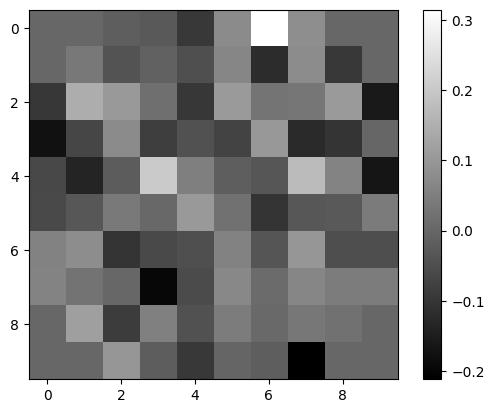

(2020, 2, 10, 10) (8080, 2, 10, 10)
(2020, 80, 80) (8080, 80, 80)


In [28]:
rng =  np.random.default_rng(rng_SEED)
n = WFS.shape[0]
train_id = np.zeros(n,np.bool)
train_id[rng.choice(n,int(train_split*n),replace=False)] = True

x_train = WFS[train_id,:,:,:]
x_val = WFS[~train_id,:,:,:]

y_train = iPSF[train_id,:,:]
y_val = iPSF[~train_id,:,:]

plt.close(0)
plt.figure(0)
plt.imshow(x_train[4,0,:,:], cmap='gray')
plt.colorbar()
plt.show()

print(x_val.shape,x_train.shape)
print(y_val.shape,y_train.shape)

## Unet

In [ ]:
import TM26_unet as unet
model = unet.build_unet(input_shape=(2,80,80), n_channels_out=1)
 

In [ ]:
device = torch.device("cuda:0" if GPU and torch.cuda.is_available() else "cpu")
